DATA Exploration

In [108]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

from scipy.stats import chi2_contingency
from pathlib import Path

plt.style.use("ggplot")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

DATA_PATH = Path(r"C:\Users\rayan\Downloads\Datasets (1)\Datasets")

In [109]:
clients = pd.read_csv(DATA_PATH / "clients.csv")
qualifications = pd.read_csv(DATA_PATH / "qualifications.csv")
promesses = pd.read_csv(DATA_PATH / "promesses.csv")
gestionnaires = pd.read_csv(DATA_PATH / "gestionnaires.csv")
connexions = pd.read_csv(DATA_PATH / "connexions.csv")
responsables = pd.read_csv(DATA_PATH / "responsables.csv")
dettes = pd.read_csv(DATA_PATH / "table_dettes.csv")


Overview

In [110]:
datasets = {
    "Clients": clients,
    "Qualifications": qualifications,
    "Promesses": promesses,
    "Gestionnaires": gestionnaires,
    "Connexions": connexions,
    "Responsables": responsables,
    "Dettes": dettes
}

for name, df in datasets.items():

    print("="*60)
    print(name)
    print("="*60)

    print("Shape :", df.shape)
    print()

    print(df.head())

    print()

Clients
Shape : (304, 8)

   id_client        nom       prenom   specialite  \
0          1  Hernandez        Louis  Agriculteur   
1          2     Bonnin       Sophie    Jardinier   
2          3     Michel    Françoise      Fermier   
3          4      Leroy        Henri   Commerçant   
4          5     Dupont  Jean-Pierre      Fermier   

                              adresse        ville                     region  \
0       138 Boulevard Anfa, Marrakech    Marrakech             Marrakech-Safi   
1     149 Avenue des FAR, Béni Mellal  Béni Mellal       Béni Mellal-Khénifra   
2  81 Rue Allal Ben Abdellah, Tétouan      Tétouan  Tanger-Tétouan-Al Hoceïma   
3         148 Avenue Hassan II, Rabat        Rabat         Rabat-Salé-Kénitra   
4        138 Avenue Hassan II, Agadir       Agadir                Souss-Massa   

   id_gestionnaire  
0                1  
1                1  
2                1  
3                1  
4                2  

Qualifications
Shape : (13115, 5)

   id_

Structure de chaque Table

In [111]:
for name, df in datasets.items():

    print("="*60)
    print(name)
    print("="*60)

    print(df.info())

    print("\nMissing values\n")

    print(df.isna().sum())

    print("\nDuplicates :", df.duplicated().sum())

    print("\n")

Clients
<class 'pandas.DataFrame'>
RangeIndex: 304 entries, 0 to 303
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   id_client        304 non-null    int64
 1   nom              304 non-null    str  
 2   prenom           304 non-null    str  
 3   specialite       304 non-null    str  
 4   adresse          304 non-null    str  
 5   ville            304 non-null    str  
 6   region           304 non-null    str  
 7   id_gestionnaire  304 non-null    int64
dtypes: int64(2), str(6)
memory usage: 42.0 KB
None

Missing values

id_client          0
nom                0
prenom             0
specialite         0
adresse            0
ville              0
region             0
id_gestionnaire    0
dtype: int64

Duplicates : 0


Qualifications
<class 'pandas.DataFrame'>
RangeIndex: 13115 entries, 0 to 13114
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype
---  ------              -------

Statistiaue Descriptive 

In [112]:
for name, df in datasets.items():

    print("="*60)
    print(name)
    print("="*60)

    print(df.describe(include="all"))

Clients
        id_client     nom   prenom   specialite  \
count   304.00000     304      304          304   
unique        NaN      40       30           24   
top           NaN  Wilson  Suzanne  Agriculteur   
freq          NaN      13       18           20   
mean    152.50000     NaN      NaN          NaN   
std      87.90146     NaN      NaN          NaN   
min       1.00000     NaN      NaN          NaN   
25%      76.75000     NaN      NaN          NaN   
50%     152.50000     NaN      NaN          NaN   
75%     228.25000     NaN      NaN          NaN   
max     304.00000     NaN      NaN          NaN   

                                 adresse        ville          region  \
count                                304          304             304   
unique                               303           15               8   
top     123 Boulevard Abdelmoumen, Rabat  Béni Mellal  Marrakech-Safi   
freq                                   2           36              57   
mean          

Verification des clés primaires

In [113]:
print("Clients :", clients.id_client.is_unique)

print("Qualifications :", qualifications.id_qualification.is_unique)

print("Promesses :", promesses.id_promesse.is_unique)

print("Gestionnaires :", gestionnaires.id_gestionnaire.is_unique)

print("Responsables :", responsables.id_responsable.is_unique)

Clients : True
Qualifications : True
Promesses : True
Gestionnaires : True
Responsables : True


Verification des clés étrangères

In [114]:
print("Unknown clients in qualifications :")

print(
    ~qualifications.id_client.isin(
        clients.id_client
    ).sum()
)

print("Unknown qualifications in promesses :")

print(
    ~promesses.id_qualification.isin(
        qualifications.id_qualification
    ).sum()
)

print("Unknown gestionnaires in clients :")

print(
    ~clients.id_gestionnaire.isin(
        gestionnaires.id_gestionnaire
    ).sum()
)

Unknown clients in qualifications :
-13116
Unknown qualifications in promesses :
-673
Unknown gestionnaires in clients :
-305


le nombre des clients 

In [115]:
print("Unique clients :", clients.id_client.nunique())

print("Unique qualifications :", qualifications.id_qualification.nunique())

print("Unique promises :", promesses.id_promesse.nunique())

Unique clients : 304
Unique qualifications : 13115
Unique promises : 672


Distrubition des status de qualfication

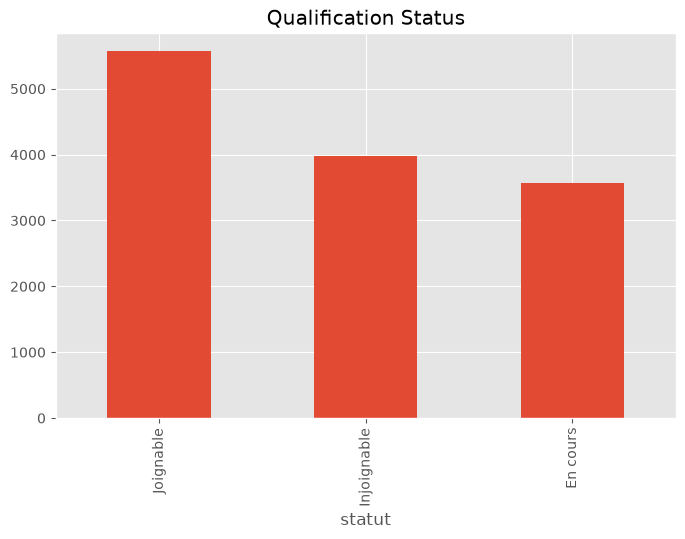

In [116]:
plt.figure(figsize=(8,5))

qualifications["statut"].value_counts().plot.bar()

plt.title("Qualification Status")

plt.show()

Distrubition de type de qualification

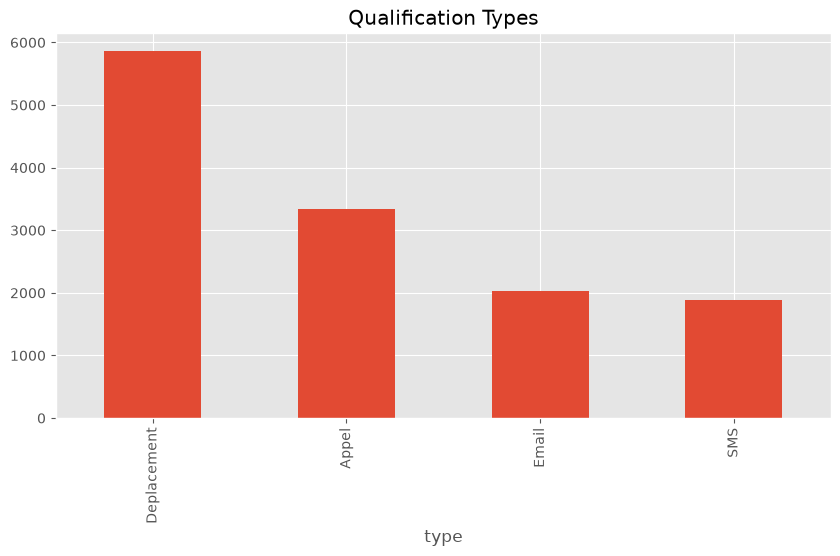

In [117]:
plt.figure(figsize=(10,5))

qualifications["type"].value_counts().plot.bar()

plt.title("Qualification Types")

plt.show()

Spécialisation des Gestionnaires

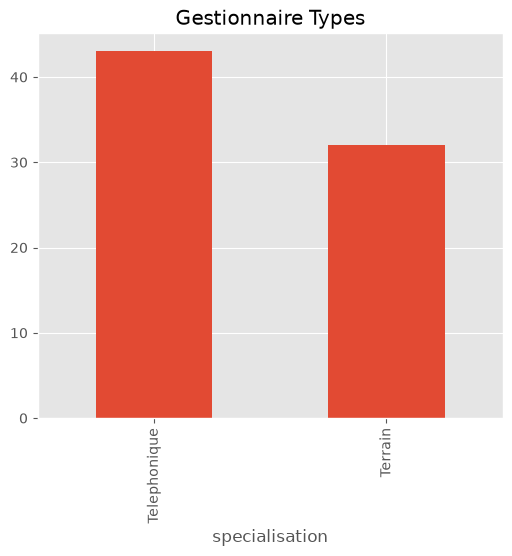

In [118]:
plt.figure(figsize=(6,5))

gestionnaires["specialisation"].value_counts().plot.bar()

plt.title("Gestionnaire Types")

plt.show()

les Clients par profession 

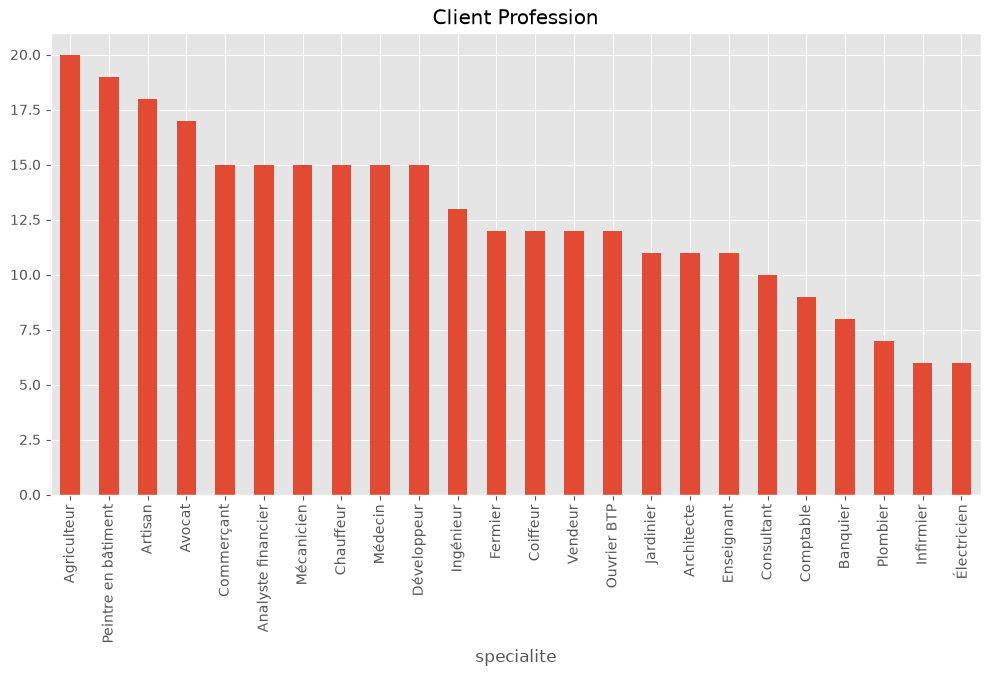

In [119]:
plt.figure(figsize=(12,6))

clients["specialite"].value_counts().plot.bar()

plt.xticks(rotation=90)

plt.title("Client Profession")

plt.show()

Les CLients par Région  

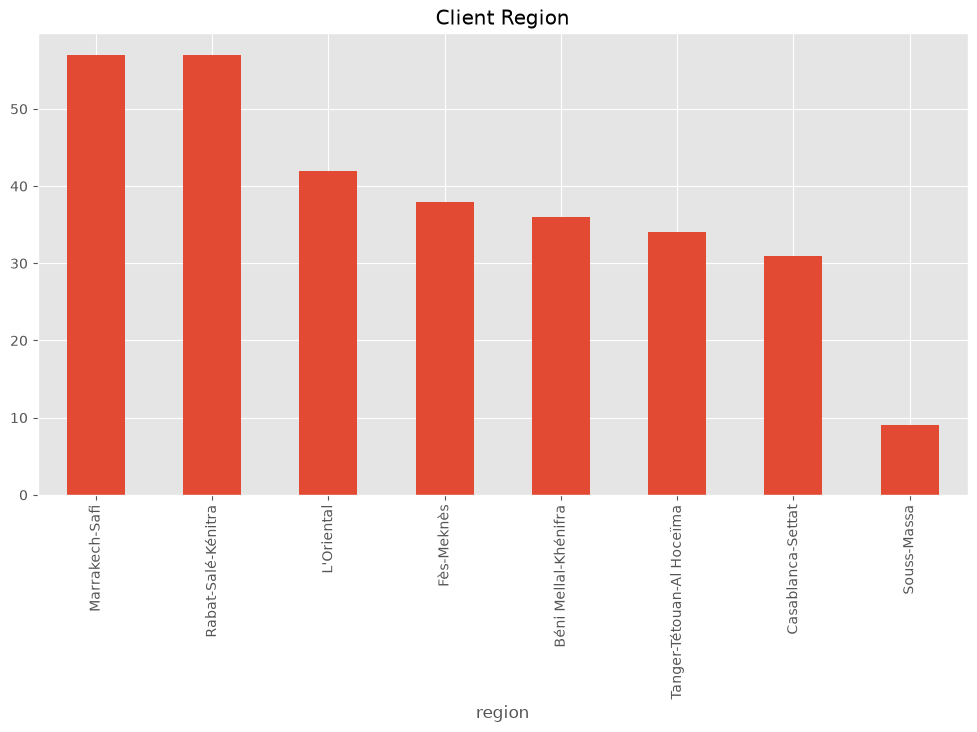

In [120]:
plt.figure(figsize=(12,6))

clients["region"].value_counts().plot.bar()

plt.xticks(rotation=90)

plt.title("Client Region")

plt.show()

Les CLients par Ville

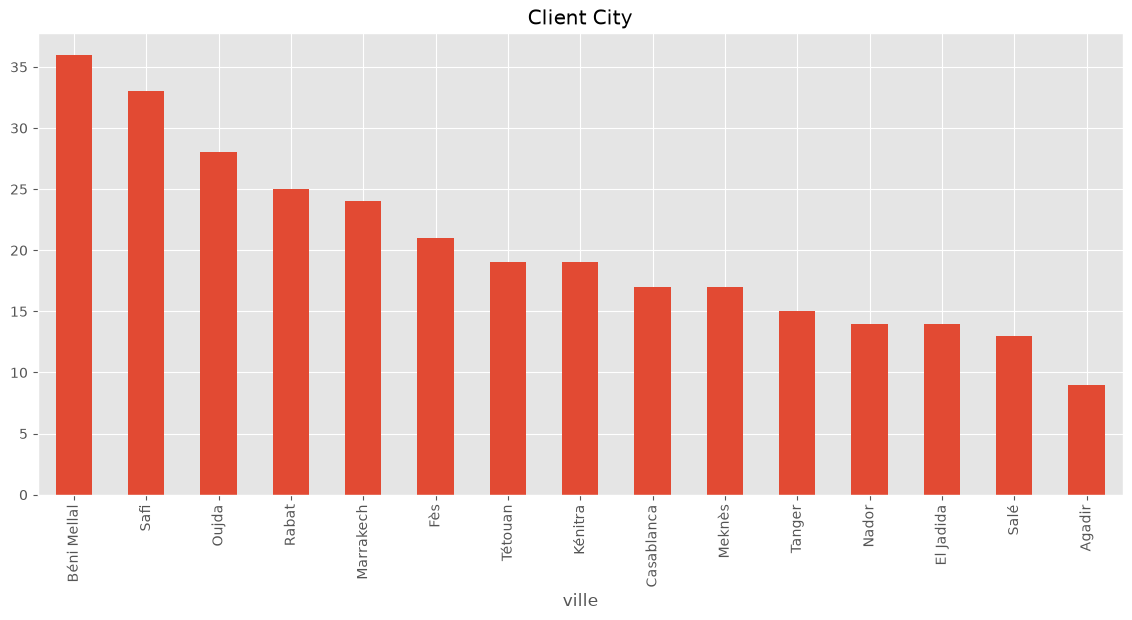

In [121]:
plt.figure(figsize=(14,6))

clients["ville"].value_counts().plot.bar()

plt.xticks(rotation=90)

plt.title("Client City")

plt.show()

Les Promesses en fct temps 

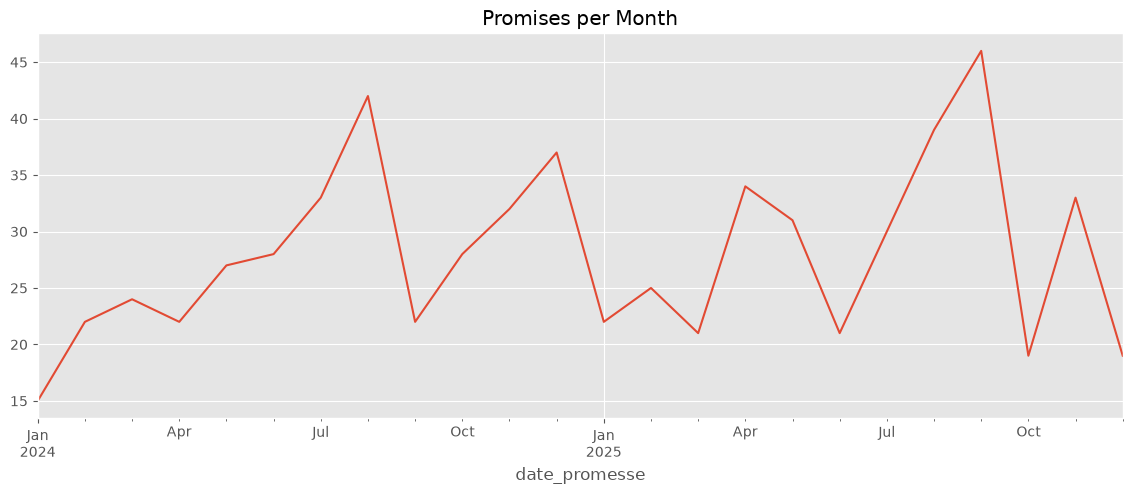

In [122]:
promesses["date_promesse"] = pd.to_datetime(
    promesses["date_promesse"]
)

(
    promesses
    .set_index("date_promesse")
    .resample("ME")
    .size()
).plot(figsize=(14,5))

plt.title("Promises per Month")

plt.show()

Qualification en fct de temps

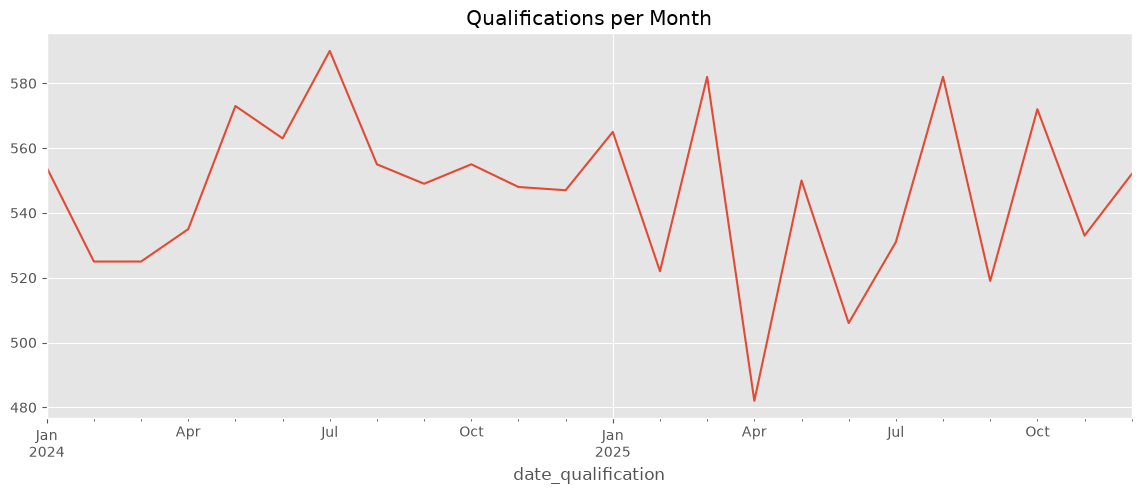

In [123]:
qualifications["date_qualification"] = pd.to_datetime(
    qualifications["date_qualification"]
)

(
    qualifications
    .set_index("date_qualification")
    .resample("ME")
    .size()
).plot(figsize=(14,5))

plt.title("Qualifications per Month")

plt.show()

Canal de Communication en fct de Statut 

In [124]:
pd.crosstab(
    qualifications["type"],
    qualifications["statut"]
)

statut,En cours,Injoignable,Joignable
type,,,
Appel,813,1187,1336
Deplacement,559,2108,3190
Email,1235,319,482
SMS,958,368,560


HeatMap de nos données

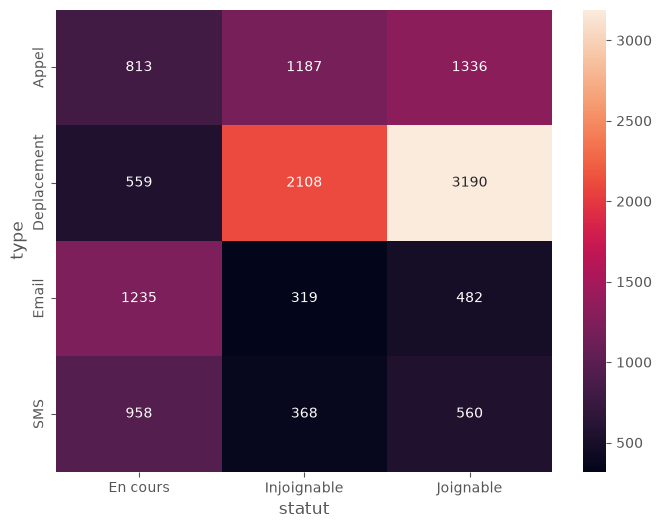

In [125]:
plt.figure(figsize=(8,6))

sns.heatmap(

    pd.crosstab(

        qualifications["type"],
        qualifications["statut"]

    ),

    annot=True,

    fmt="d"

)

plt.show()

Quel profession reçoit plus de contact

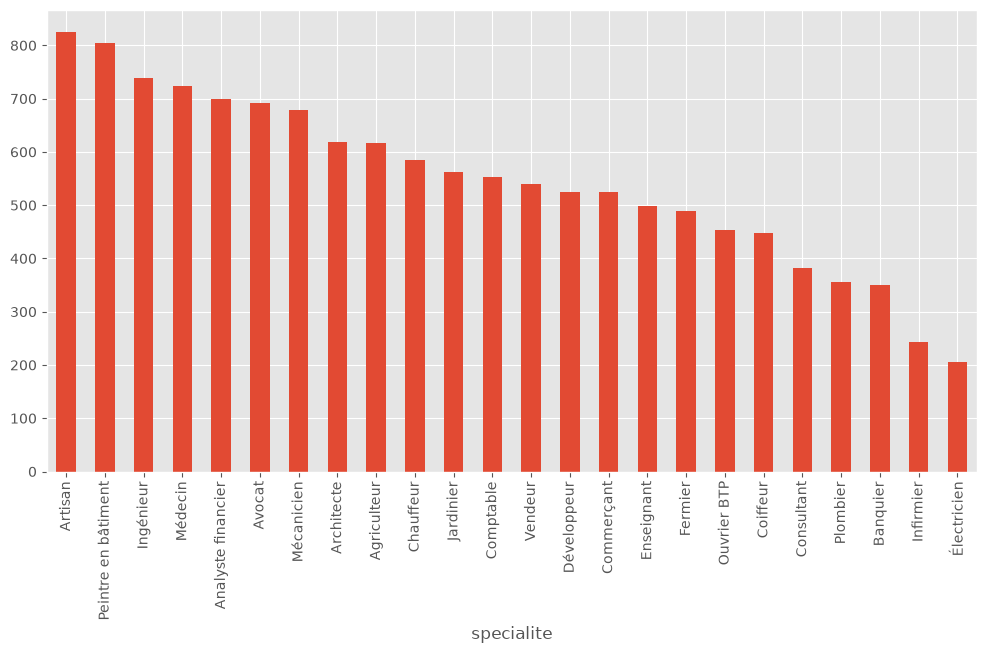

In [126]:
temp = qualifications.merge(

    clients[
        ["id_client","specialite"]
    ],

    on="id_client"

)

temp["specialite"].value_counts().plot.bar(figsize=(12,6))

plt.xticks(rotation=90)

plt.show()

les Professions qui obtient plus de promesses 

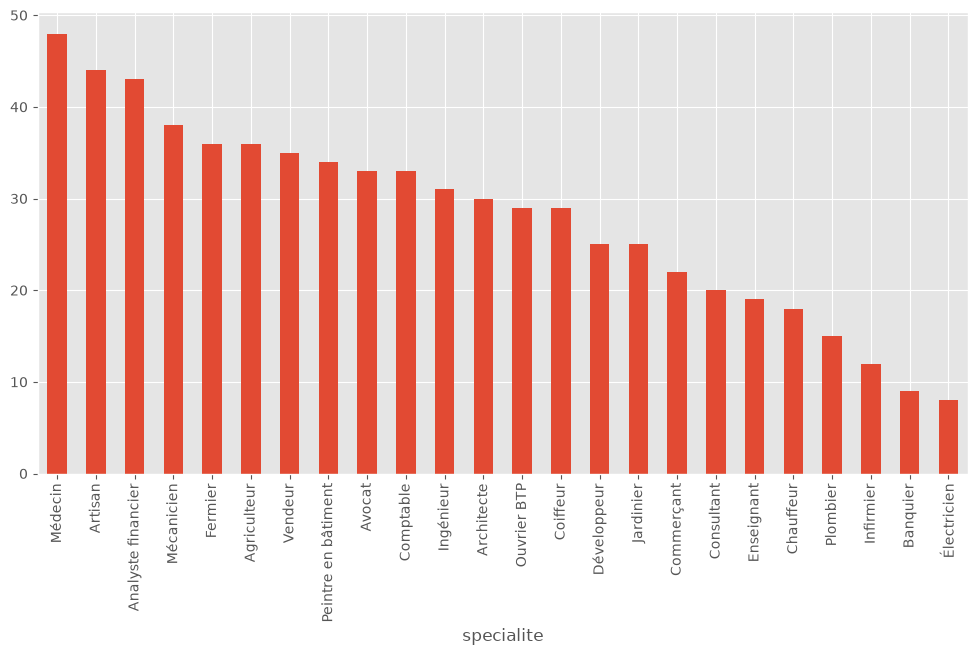

In [127]:
temp = (

    promesses.merge(

        qualifications[
            ["id_qualification","id_client"]
        ],

        on="id_qualification"

    )

    .merge(

        clients[
            ["id_client","specialite"]
        ],

        on="id_client"

    )

)

temp["specialite"].value_counts().plot.bar(figsize=(12,6))

plt.xticks(rotation=90)

plt.show()

Taux de Promesses par profession 

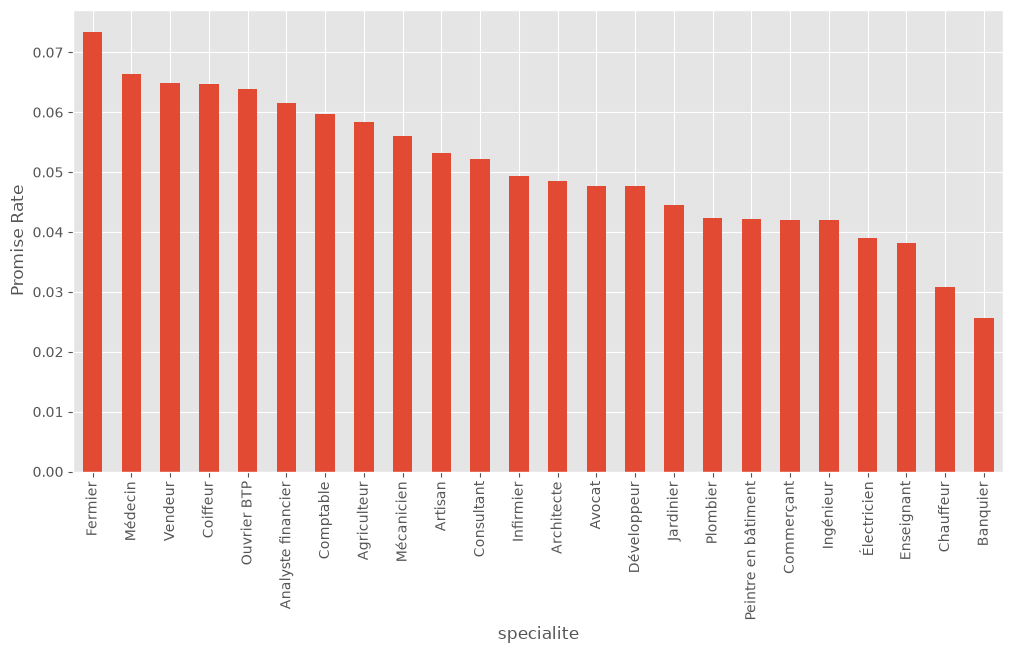

specialite
Fermier                0.073469
Médecin                0.066298
Vendeur                0.064815
Coiffeur               0.064732
Ouvrier BTP            0.063877
Analyste financier     0.061516
Comptable              0.059675
Agriculteur            0.058347
Mécanicien             0.056047
Artisan                0.053269
Consultant             0.052219
Infirmier              0.049383
Architecte             0.048465
Avocat                 0.047688
Développeur            0.047619
Jardinier              0.044484
Plombier               0.042254
Peintre en bâtiment    0.042236
Commerçant             0.041985
Ingénieur              0.041949
Électricien            0.039024
Enseignant             0.038076
Chauffeur              0.030769
Banquier               0.025714
Name: promise, dtype: float64

In [128]:
contacts = qualifications.merge(

    clients[
        ["id_client","specialite"]
    ],

    on="id_client"

)

contacts["promise"] = contacts[
    "id_qualification"
].isin(
    promesses["id_qualification"]
)

result = (

    contacts

    .groupby("specialite")["promise"]

    .mean()

    .sort_values(ascending=False)

)

plt.figure(figsize=(12,6))

result.plot.bar()

plt.ylabel("Promise Rate")

plt.xticks(rotation=90)

plt.show()

display(result)

Taux de promesses par canal de communication

In [129]:
contacts.groupby("type")["promise"].mean().sort_values()

type
Email          0.028978
SMS            0.035525
Appel          0.049460
Deplacement    0.065050
Name: promise, dtype: float64

Taux de promesses par statut

In [130]:
contacts.groupby("statut")["promise"].mean()

statut
En cours       0.00000
Injoignable    0.00000
Joignable      0.12069
Name: promise, dtype: float64

Types de gestionnaires par profession

In [131]:
temp = clients.merge(

    gestionnaires[
        ["id_gestionnaire","specialisation"]
    ],

    on="id_gestionnaire"

)

pd.crosstab(

    temp.specialite,

    temp.specialisation,

    normalize="index"

)

specialisation,Telephonique,Terrain
specialite,,
Agriculteur,0.550000,0.450000
Analyste financier,0.466667,0.533333
Architecte,0.454545,0.545455
Artisan,0.611111,0.388889
Avocat,0.705882,0.294118
Banquier,0.875000,0.125000
Chauffeur,0.866667,0.133333
Coiffeur,0.250000,0.750000
Commerçant,0.666667,0.333333


distibution de l'historique clients de qualifications 

<Axes: >

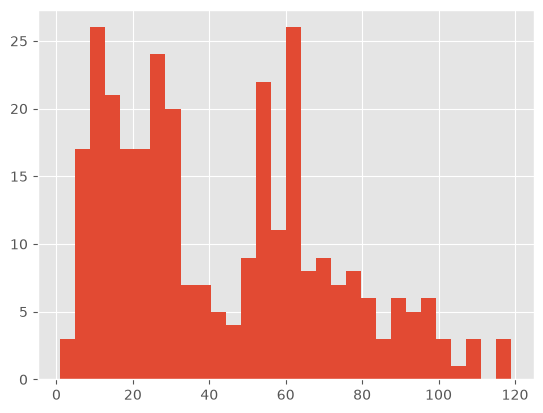

In [132]:
qualifications.groupby("id_client").size().hist(bins=30)

historique de promesses par client 

In [133]:
promesses.merge(
    qualifications[["id_qualification", "id_client"]],
    on="id_qualification"
).groupby("id_client").size().describe()

count    223.000000
mean       3.013453
std        2.220867
min        1.000000
25%        1.000000
50%        2.000000
75%        4.000000
max       10.000000
dtype: float64

delai promesse et 1ere avance 

count    672.000000
mean       4.555060
std        1.754688
min        2.000000
25%        3.000000
50%        5.000000
75%        6.000000
max        7.000000
Name: delai_avance, dtype: float64


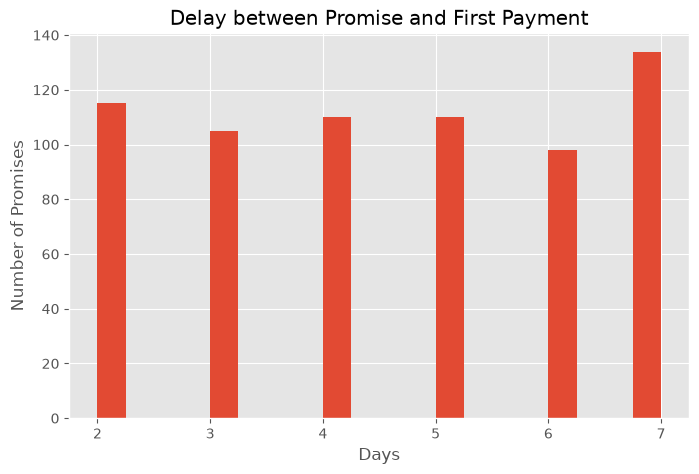

In [134]:
promesses["date_promesse"] = pd.to_datetime(promesses["date_promesse"])
promesses["date_1ere_avance"] = pd.to_datetime(promesses["date_1ere_avance"])

promesses["delai_avance"] = (
    promesses["date_1ere_avance"] -
    promesses["date_promesse"]
).dt.days

print(promesses["delai_avance"].describe())

plt.figure(figsize=(8,5))
plt.hist(promesses["delai_avance"], bins=20)
plt.title("Delay between Promise and First Payment")
plt.xlabel("Days")
plt.ylabel("Number of Promises")
plt.show()

efficacité de canal de communication

In [135]:
contacts = qualifications.merge(
    promesses[["id_qualification"]],
    on="id_qualification",
    how="left",
    indicator=True
)

contacts["promise"] = (
    contacts["_merge"] == "both"
).astype(int)

contacts.drop(columns="_merge", inplace=True)

In [136]:
channel_stats = (
    contacts
    .groupby("type")
    .agg(
        Contacts=("id_qualification", "count"),
        Promesses=("promise", "sum"),
        Taux_Promesse=("promise", "mean")
    )
    .sort_values("Taux_Promesse", ascending=False)
)

display(channel_stats)

,Contacts,Promesses,Taux_Promesse
type,,,
Deplacement,5857,381,0.065050
Appel,3336,165,0.049460
SMS,1886,67,0.035525
Email,2036,59,0.028978


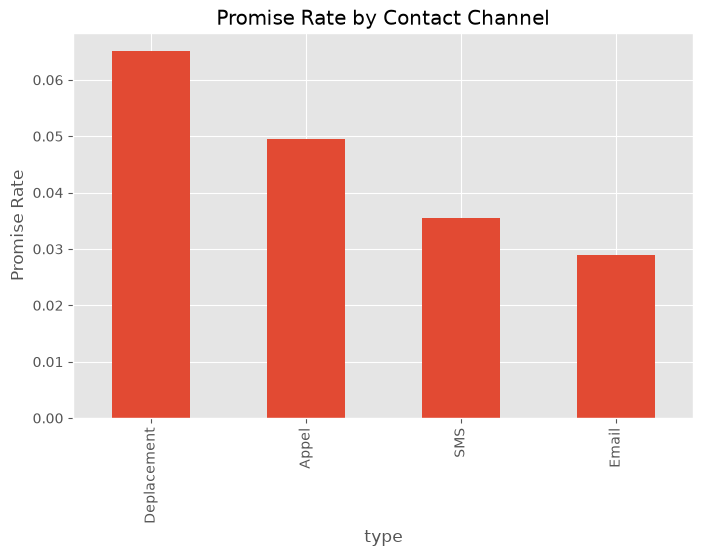

In [137]:
plt.figure(figsize=(8,5))

channel_stats["Taux_Promesse"].plot(
    kind="bar"
)

plt.ylabel("Promise Rate")
plt.title("Promise Rate by Contact Channel")

plt.show()

Efficacité des Gestionnaires

In [138]:
gestionnaire_stats = (

    qualifications

    .merge(
        clients[
            ["id_client", "id_gestionnaire"]
        ],
        on="id_client"
    )

    .merge(
        gestionnaires[
            ["id_gestionnaire", "specialisation"]
        ],
        on="id_gestionnaire"
    )

)

gestionnaire_stats["promise"] = (
    gestionnaire_stats["id_qualification"]
    .isin(promesses["id_qualification"])
).astype(int)

In [139]:
performance = (

    gestionnaire_stats

    .groupby(
        [
            "id_gestionnaire",
            "specialisation"
        ]
    )

    .agg(
        Contacts=("id_qualification", "count"),
        Promesses=("promise", "sum"),
        Taux_Promesse=("promise", "mean")
    )

    .sort_values(
        "Taux_Promesse",
        ascending=False
    )

)

display(performance)

,,Contacts,Promesses,Taux_Promesse
id_gestionnaire,specialisation,,,
63,Terrain,24,3,0.125000
68,Terrain,251,23,0.091633
24,Terrain,330,30,0.090909
59,Terrain,33,3,0.090909
70,Terrain,238,20,0.084034
61,Terrain,36,3,0.083333
29,Terrain,526,40,0.076046
56,Telephonique,53,4,0.075472
14,Terrain,98,7,0.071429


In [140]:
performance_specialisation = (

    performance

    .reset_index()

    .groupby("specialisation")

    .agg(
        Moyenne_Taux=("Taux_Promesse", "mean"),
        Total_Contacts=("Contacts", "sum"),
        Total_Promesses=("Promesses", "sum")
    )

)

display(performance_specialisation)

,Moyenne_Taux,Total_Contacts,Total_Promesses
specialisation,,,
Telephonique,0.038754,7258,291
Terrain,0.060890,5857,381


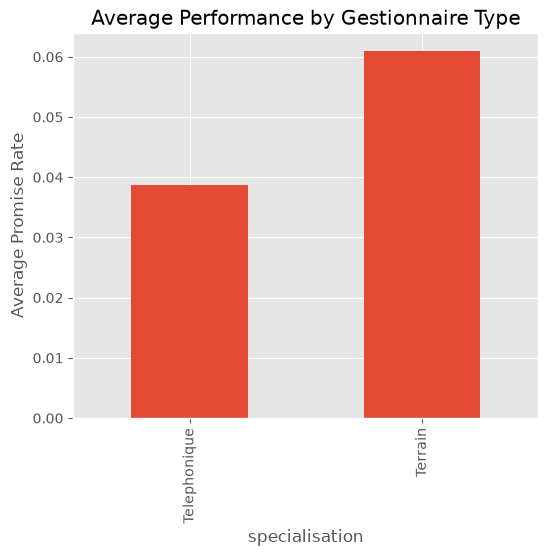

In [141]:
performance_specialisation["Moyenne_Taux"].plot(
    kind="bar",
    figsize=(6,5)
)

plt.ylabel("Average Promise Rate")
plt.title("Average Performance by Gestionnaire Type")

plt.show()

Logique chronologique 

est ce que chaque promesse est apres un contact

In [142]:
verification = (

    promesses

    .merge(

        qualifications[
            [
                "id_qualification",
                "date_qualification"
            ]
        ],

        on="id_qualification"

    )

)

verification["date_qualification"] = pd.to_datetime(
    verification["date_qualification"]
)

verification["date_promesse"] = pd.to_datetime(
    verification["date_promesse"]
)

verification["date_1ere_avance"] = pd.to_datetime(
    verification["date_1ere_avance"]
)

Promesse Impossible (Promesse donné avant un contact)

In [143]:
promesses_avant_qualification = verification[
    verification["date_promesse"] <
    verification["date_qualification"]
]

print(
    "Promises before qualification :",
    len(promesses_avant_qualification)
)

display(promesses_avant_qualification.head())

Promises before qualification : 0


,id_promesse,id_qualification,date_promesse,date_1ere_avance,delai_avance,date_qualification


1ere avance impossible (1ere avance avant une promesse)

In [144]:
avance_avant_promesse = verification[
    verification["date_1ere_avance"] <
    verification["date_promesse"]
]

print(
    "First payment before promise :",
    len(avance_avant_promesse)
)

display(avance_avant_promesse.head())

First payment before promise : 0


,id_promesse,id_qualification,date_promesse,date_1ere_avance,delai_avance,date_qualification


Temps apres une qualification et une promesse

In [145]:
verification["delai_contact_promesse"] = (

    verification["date_promesse"] -
    verification["date_qualification"]

).dt.days

print(
    verification[
        "delai_contact_promesse"
    ].describe()
)

count    672.000000
mean      10.418155
std        5.647032
min        1.000000
25%        6.000000
50%       10.000000
75%       15.000000
max       20.000000
Name: delai_contact_promesse, dtype: float64


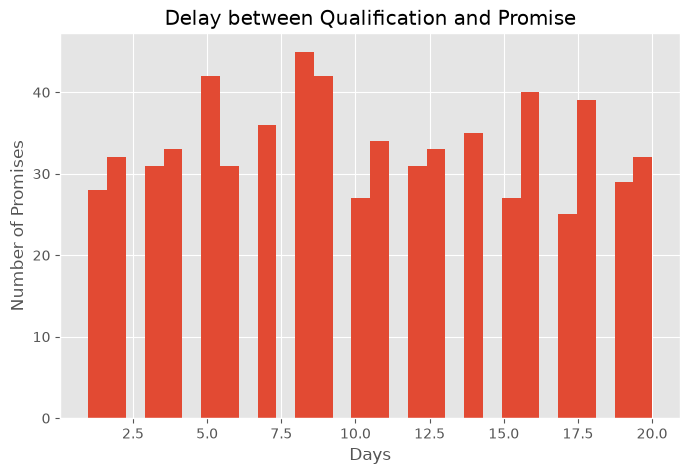

In [146]:
plt.figure(figsize=(8,5))

plt.hist(
    verification["delai_contact_promesse"],
    bins=30
)

plt.title(
    "Delay between Qualification and Promise"
)

plt.xlabel("Days")

plt.ylabel("Number of Promises")

plt.show()

**EST CE QUE L'HISTORIQUE DU CLIENT AFFECTE SON COMPORTEMENT FUTURE ? **

Creation du TimeLine :

In [147]:
timeline = (

    qualifications

    .merge(

        clients[
            [
                "id_client",
                "specialite",
                "ville",
                "region"
            ]
        ],

        on="id_client"

    )

)

In [148]:
timeline["promise"] = (

    timeline["id_qualification"]

    .isin(
        promesses["id_qualification"]
    )

).astype(int)

In [149]:
timeline["date_qualification"] = pd.to_datetime(
    timeline["date_qualification"]
)

In [150]:
timeline = timeline.sort_values(

    [
        "id_client",
        "date_qualification"
    ]

).reset_index(drop=True)

print("TimeLine created successfully!")

TimeLine created successfully!


les contacts précédents de chaque client :

In [151]:
timeline["previous_contacts"] = (

    timeline

    .groupby("id_client")

    .cumcount()

)

les promesses précédents :

In [152]:
timeline["previous_promises"] = (

    timeline

    .groupby("id_client")["promise"]

    .cumsum()

    -

    timeline["promise"]

)

Taux de promesses avant le contact courrant 

In [153]:
timeline["previous_promise_rate"] = (

    timeline["previous_promises"]

    /

    timeline["previous_contacts"]

)

gestion de la division par 0 pour calculer le Taux de promesses avant le contact courrant  :

In [154]:
timeline["previous_promise_rate"] = (

    timeline["previous_promise_rate"]

    .fillna(0)

)

Historique de joignabilité :

In [155]:
timeline["joignable"] = (
    timeline["statut"]=="Joignable"
).astype(int)

In [156]:
timeline["previous_joignable"] = (

    timeline

    .groupby("id_client")["joignable"]

    .cumsum()

    -

    timeline["joignable"]

)

verification si l'historique est important :

In [157]:
timeline.groupby(

    "previous_promises"

)["promise"].mean()

previous_promises
0     0.043000
1     0.048797
2     0.062307
3     0.074697
4     0.055260
5     0.053883
6     0.050704
7     0.058201
8     0.051724
9     0.136364
10    0.000000
Name: promise, dtype: float64

Visualisation :

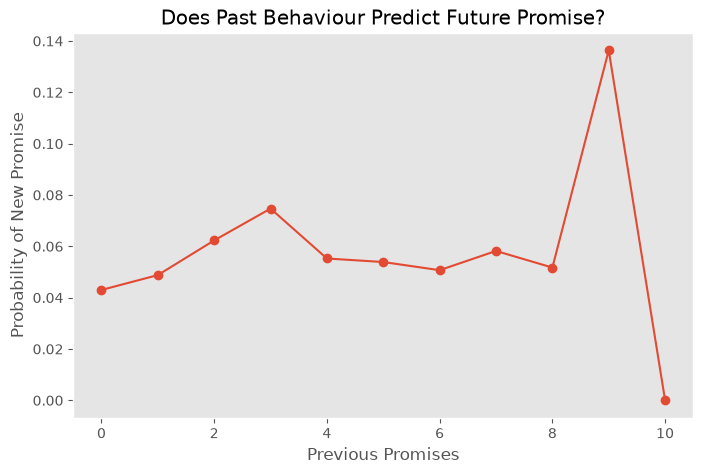

In [158]:
result = (

    timeline

    .groupby(

        "previous_promises"

    )["promise"]

    .mean()

)

plt.figure(figsize=(8,5))

plt.plot(

    result.index,

    result.values,

    marker="o"

)

plt.xlabel("Previous Promises")

plt.ylabel("Probability of New Promise")

plt.title("Does Past Behaviour Predict Future Promise?")

plt.grid()

plt.show()

clients avec aucune promesse precedente VS qui ont au moins une seul promesse precedente :

In [159]:
timeline["had_previous_promise"] = (
    timeline["previous_promises"]>0
)

In [160]:
timeline.groupby(

    "had_previous_promise"

)["promise"].agg(

    ["count","mean"]

)

,count,mean
had_previous_promise,,
False,5186,0.043000
True,7929,0.056628


Quelles sont les variables qui influencent la probabilité d'une pomesse 

In [161]:
analysis = timeline.copy()

In [162]:
analysis = analysis[[
    "promise",
    "type",
    "statut",
    "specialite",
    "ville",
    "region",
    "previous_contacts",
    "previous_promises",
    "previous_promise_rate"
]]

In [163]:
analysis.head()

,promise,type,statut,specialite,ville,region,previous_contacts,previous_promises,previous_promise_rate
0,0,Appel,Injoignable,Agriculteur,Marrakech,Marrakech-Safi,0,0,0.0
1,0,Email,En cours,Agriculteur,Marrakech,Marrakech-Safi,1,0,0.0
2,0,Appel,Joignable,Agriculteur,Marrakech,Marrakech-Safi,2,0,0.0
3,0,Appel,En cours,Agriculteur,Marrakech,Marrakech-Safi,3,0,0.0
4,0,Appel,Injoignable,Agriculteur,Marrakech,Marrakech-Safi,4,0,0.0


statistiques de "profession" 

In [164]:
profession_stats = (

    analysis

    .groupby("specialite")

    .agg(

        Contacts=("promise","count"),

        Promesses=("promise","sum"),

        Promise_Rate=("promise","mean")

    )

    .sort_values(
        "Promise_Rate",
        ascending=False
    )

)

display(profession_stats)

,Contacts,Promesses,Promise_Rate
specialite,,,
Fermier,490,36,0.073469
Médecin,724,48,0.066298
Vendeur,540,35,0.064815
Coiffeur,448,29,0.064732
Ouvrier BTP,454,29,0.063877
Analyste financier,699,43,0.061516
Comptable,553,33,0.059675
Agriculteur,617,36,0.058347
Mécanicien,678,38,0.056047


statistique de ville 

In [165]:
ville_stats = (

    analysis

    .groupby("ville")

    .agg(

        Contacts=("promise","count"),

        Promesses=("promise","sum"),

        Promise_Rate=("promise","mean")

    )

    .sort_values(
        "Promise_Rate",
        ascending=False
    )

)

display(ville_stats)

,Contacts,Promesses,Promise_Rate
ville,,,
Nador,511,35,0.068493
Béni Mellal,1446,97,0.067082
Tanger,829,50,0.060314
Safi,1907,113,0.059255
Salé,319,18,0.056426
Marrakech,1323,72,0.054422
Rabat,776,41,0.052835
Agadir,395,20,0.050633
Fès,748,37,0.049465


statistique Region

In [166]:
Region_stats = (

    analysis

    .groupby("region")

    .agg(

        Contacts=("promise","count"),

        Promesses=("promise","sum"),

        Promise_Rate=("promise","mean")

    )

    .sort_values(
        "Promise_Rate",
        ascending=False
    )

)

display(Region_stats)

,Contacts,Promesses,Promise_Rate
region,,,
Béni Mellal-Khénifra,1446,97,0.067082
Marrakech-Safi,3230,185,0.057276
Souss-Massa,395,20,0.050633
Tanger-Tétouan-Al Hoceïma,1805,89,0.049307
Rabat-Salé-Kénitra,1910,93,0.048691
Fès-Meknès,1271,60,0.047207
L'Oriental,1744,82,0.047018
Casablanca-Settat,1314,46,0.035008


statistique de type de contact 

In [167]:
contact_stats = (

    analysis

    .groupby("type")

    .agg(

        Contacts=("promise","count"),

        Promesses=("promise","sum"),

        Promise_Rate=("promise","mean")

    )

    .sort_values(
        "Promise_Rate",
        ascending=False
    )

)

display(contact_stats)

,Contacts,Promesses,Promise_Rate
type,,,
Deplacement,5857,381,0.065050
Appel,3336,165,0.049460
SMS,1886,67,0.035525
Email,2036,59,0.028978


In [168]:
statut_stats = (

    analysis

    .groupby("statut")

    .agg(

        Contacts=("promise","count"),

        Promesses=("promise","sum"),

        Promise_Rate=("promise","mean")

    )

    .sort_values(
        "Promise_Rate",
        ascending=False
    )

)

display(statut_stats)

,Contacts,Promesses,Promise_Rate
statut,,,
Joignable,5568,672,0.12069
En cours,3565,0,0.00000
Injoignable,3982,0,0.00000


Realtions statiques entre les Features

si le resultat < 0.5 on considere les features ne sont pas independant  

In [169]:
table = pd.crosstab(

    analysis["specialite"],

    analysis["promise"]

)

chi2,p,_,_ = chi2_contingency(table)

print(p)

0.06210082501374976


In [170]:
table = pd.crosstab(

    analysis["ville"],

    analysis["promise"]

)

chi2,p,_,_ = chi2_contingency(table)

print(p)

0.0029473871708856343


In [171]:
table = pd.crosstab(

    analysis["region"],

    analysis["promise"]

)

chi2,p,_,_ = chi2_contingency(table)

print(p)

0.010025688656208759


In [172]:
table = pd.crosstab(

    analysis["statut"],

    analysis["promise"]

)

chi2,p,_,_ = chi2_contingency(table)

print(p)

3.3946662295736776e-209


In [173]:
table = pd.crosstab(

    analysis["type"],

    analysis["promise"]

)

chi2,p,_,_ = chi2_contingency(table)

print(p)

1.4114012555348081e-11


In [174]:

temp = analysis.copy()

for c in temp.select_dtypes(include=["object","string"]).columns:

    temp[c] = LabelEncoder().fit_transform(temp[c].astype(str))

combien d'informmation chaque feature nous donne sur la variable cible 

In [175]:
from sklearn.feature_selection import mutual_info_classif

X = temp.drop(columns="promise")

y = temp["promise"]

mi = mutual_info_classif(

    X,

    y,

    random_state=42

)

mi = pd.Series(

    mi,

    index=X.columns

).sort_values(ascending=False)

display(mi)

statut                   0.048026
region                   0.002838
type                     0.002456
specialite               0.002422
previous_promises        0.002209
previous_promise_rate    0.002007
ville                    0.000989
previous_contacts        0.000000
dtype: float64

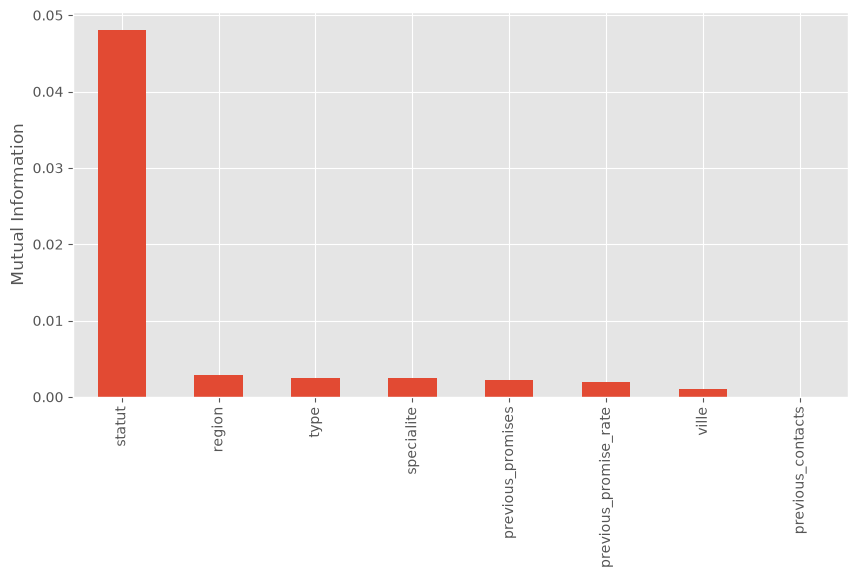

In [176]:
mi.plot.bar(figsize=(10,5))

plt.ylabel("Mutual Information")

plt.show()

Random Forest Feature Importance

In [177]:
rf = RandomForestClassifier(

    n_estimators=300,

    random_state=42

)

train

In [178]:
rf.fit(

    X,

    y

)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

Importance

In [179]:
importance = pd.Series(

    rf.feature_importances_,

    index=X.columns

).sort_values(ascending=False)

display(importance)

previous_contacts        0.308808
specialite               0.202404
previous_promise_rate    0.184723
statut                   0.077226
ville                    0.075544
previous_promises        0.059135
region                   0.049383
type                     0.042775
dtype: float64

plot

<Axes: >

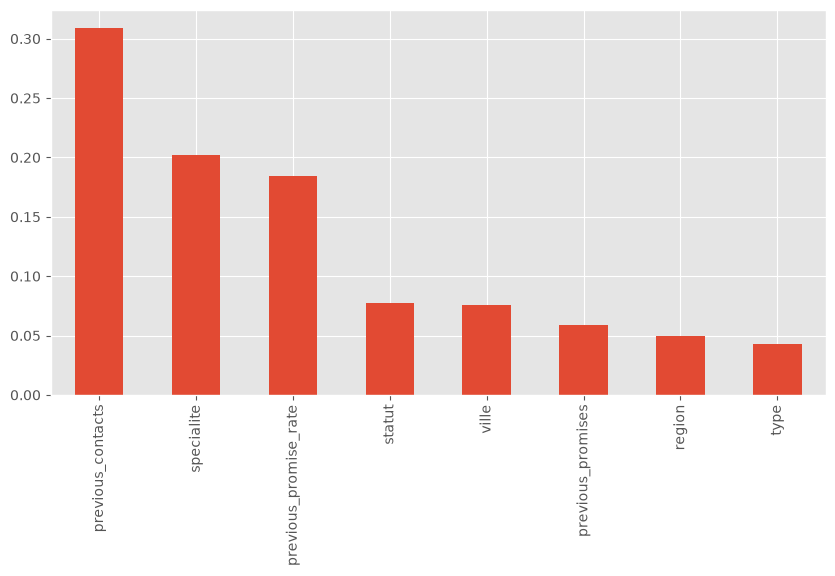

In [180]:
importance.plot.bar(figsize=(10,5))

 Importance de permutation

In [181]:
result = permutation_importance(

    rf,

    X,

    y,

    random_state=42,

    n_repeats=10

)

In [182]:
perm = pd.Series(

    result.importances_mean,

    index=X.columns

).sort_values(ascending=False)

display(perm)

previous_contacts        0.058079
specialite               0.045909
previous_promise_rate    0.037697
ville                    0.036256
statut                   0.033244
type                     0.032207
region                   0.031811
previous_promises        0.028845
dtype: float64

Exploration de la table dettes 

In [183]:
print("=" * 60)
print("Dettes")
print("=" * 60)

print("\nShape:")
print(dettes.shape)

print("\nColumns:")
print(dettes.columns.tolist())

print("\nInfo:")
print(dettes.info())

print("\nFirst 5 rows:")
display(dettes.head())

print("\nDescribe:")
display(dettes.describe(include="all"))

Dettes

Shape:
(304, 22)

Columns:
['id_dette', 'id_client', 'nom', 'prenom', 'specialite', 'adresse', 'ville', 'region', 'montant_initial', 'montant_restant', 'mensualite', 'date_debut', 'date_echeance', 'taux_interet', 'type_credit', 'revenu_mensuel', 'taux_endettement', 'nb_retards', 'jours_retard', 'score_credit', 'statut_dette', 'statut_paiement']

Info:
<class 'pandas.DataFrame'>
RangeIndex: 304 entries, 0 to 303
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id_dette          304 non-null    int64  
 1   id_client         304 non-null    int64  
 2   nom               304 non-null    str    
 3   prenom            304 non-null    str    
 4   specialite        304 non-null    str    
 5   adresse           304 non-null    str    
 6   ville             304 non-null    str    
 7   region            304 non-null    str    
 8   montant_initial   304 non-null    int64  
 9   montant_restant   304 

,id_dette,id_client,nom,prenom,specialite,adresse,ville,region,montant_initial,montant_restant,mensualite,date_debut,date_echeance,taux_interet,type_credit,revenu_mensuel,taux_endettement,nb_retards,jours_retard,score_credit,statut_dette,statut_paiement
0,1,1,Hernandez,Louis,Agriculteur,"138 Boulevard Anfa, Marrakech",Marrakech,Marrakech-Safi,264208,78334,11008.67,2024-01-01,2028-01-01,6.57,Immobilier,11920,92.4,6,89,546,En retard,Non payé
1,2,2,Bonnin,Sophie,Jardinier,"149 Avenue des FAR, Béni Mellal",Béni Mellal,Béni Mellal-Khénifra,191171,13678,7965.46,2024-01-01,2028-01-01,4.24,Auto,17847,44.6,4,128,620,En retard,Non payé
2,3,3,Michel,Françoise,Fermier,"81 Rue Allal Ben Abdellah, Tétouan",Tétouan,Tanger-Tétouan-Al Hoceïma,253570,229145,7043.61,2024-01-01,2028-01-01,5.48,Immobilier,6498,108.4,5,176,561,En retard,Non payé
3,4,4,Leroy,Henri,Commerçant,"148 Avenue Hassan II, Rabat",Rabat,Rabat-Salé-Kénitra,178747,163076,2979.12,2024-01-01,2028-01-01,6.56,Immobilier,26562,11.2,5,100,571,En retard,Non payé
4,5,5,Dupont,Jean-Pierre,Fermier,"138 Avenue Hassan II, Agadir",Agadir,Souss-Massa,101511,22476,2819.75,2024-01-01,2028-01-01,3.67,Professionnel,13573,20.8,8,169,497,En retard,Non payé



Describe:


,id_dette,id_client,nom,prenom,specialite,adresse,ville,region,montant_initial,montant_restant,mensualite,date_debut,date_echeance,taux_interet,type_credit,revenu_mensuel,taux_endettement,nb_retards,jours_retard,score_credit,statut_dette,statut_paiement
count,304.00000,304.00000,304,304,304,304,304,304,304.000000,304.000000,304.000000,304,304,304.000000,304,304.000000,304.000000,304.000000,304.000000,304.000000,304,304
unique,NaN,NaN,40,30,24,303,15,8,NaN,NaN,NaN,1,1,NaN,4,NaN,NaN,NaN,NaN,NaN,2,2
top,NaN,NaN,Wilson,Suzanne,Agriculteur,"123 Boulevard Abdelmoumen, Rabat",Béni Mellal,Marrakech-Safi,NaN,NaN,NaN,2024-01-01,2028-01-01,NaN,Auto,NaN,NaN,NaN,NaN,NaN,En retard,Non payé
freq,NaN,NaN,13,18,20,2,36,57,NaN,NaN,NaN,304,304,NaN,97,NaN,NaN,NaN,NaN,NaN,278,223
mean,152.50000,152.50000,NaN,NaN,NaN,NaN,NaN,NaN,157684.529605,75651.453947,4316.226118,NaN,NaN,5.962730,NaN,17118.266447,34.061842,3.986842,86.868421,609.121711,NaN,NaN
std,87.90146,87.90146,NaN,NaN,NaN,NaN,NaN,NaN,85332.563232,66026.649474,2953.884889,NaN,NaN,1.694072,NaN,7683.126858,36.073560,2.535521,54.987089,91.707788,NaN,NaN
min,1.00000,1.00000,NaN,NaN,NaN,NaN,NaN,NaN,15489.000000,44.000000,316.820000,NaN,NaN,3.000000,NaN,4026.000000,1.600000,0.000000,0.000000,440.000000,NaN,NaN
25%,76.75000,76.75000,NaN,NaN,NaN,NaN,NaN,NaN,76173.750000,23715.250000,1875.607500,NaN,NaN,4.477500,NaN,10366.500000,10.800000,2.000000,38.750000,534.000000,NaN,NaN
50%,152.50000,152.50000,NaN,NaN,NaN,NaN,NaN,NaN,160493.000000,51760.000000,3941.765000,NaN,NaN,6.020000,NaN,17249.500000,22.450000,4.000000,83.500000,617.000000,NaN,NaN
75%,228.25000,228.25000,NaN,NaN,NaN,NaN,NaN,NaN,237617.500000,114466.500000,6034.142500,NaN,NaN,7.400000,NaN,24350.000000,41.675000,6.000000,135.000000,689.000000,NaN,NaN


In [184]:
print("Duplicate rows :", dettes.duplicated().sum())

print("\nDuplicate id_client :", dettes["id_client"].duplicated().sum())

print("\nUnique clients :", dettes["id_client"].nunique())

Duplicate rows : 0

Duplicate id_client : 0

Unique clients : 304


verification de realtion entre dettes et Clients 

In [185]:
print("Clients :", len(clients))
print("Debt rows :", len(dettes))

print()

print("Clients in both tables :",
      dettes["id_client"].isin(clients["id_client"]).sum())

print("Debt clients missing from clients.csv :",
      (~dettes["id_client"].isin(clients["id_client"])).sum())

print("Clients without debt :",
      (~clients["id_client"].isin(dettes["id_client"])).sum())

Clients : 304
Debt rows : 304

Clients in both tables : 304
Debt clients missing from clients.csv : 0
Clients without debt : 0


Merge dettes + Clients 

In [186]:
debt_clients = dettes.merge(
    clients,
    on="id_client",
    how="left"
)

print(debt_clients.shape)

display(debt_clients.head())

(304, 29)


,id_dette,id_client,nom_x,prenom_x,specialite_x,adresse_x,ville_x,region_x,montant_initial,montant_restant,mensualite,date_debut,date_echeance,taux_interet,type_credit,revenu_mensuel,taux_endettement,nb_retards,jours_retard,score_credit,statut_dette,statut_paiement,nom_y,prenom_y,specialite_y,adresse_y,ville_y,region_y,id_gestionnaire
0,1,1,Hernandez,Louis,Agriculteur,"138 Boulevard Anfa, Marrakech",Marrakech,Marrakech-Safi,264208,78334,11008.67,2024-01-01,2028-01-01,6.57,Immobilier,11920,92.4,6,89,546,En retard,Non payé,Hernandez,Louis,Agriculteur,"138 Boulevard Anfa, Marrakech",Marrakech,Marrakech-Safi,1
1,2,2,Bonnin,Sophie,Jardinier,"149 Avenue des FAR, Béni Mellal",Béni Mellal,Béni Mellal-Khénifra,191171,13678,7965.46,2024-01-01,2028-01-01,4.24,Auto,17847,44.6,4,128,620,En retard,Non payé,Bonnin,Sophie,Jardinier,"149 Avenue des FAR, Béni Mellal",Béni Mellal,Béni Mellal-Khénifra,1
2,3,3,Michel,Françoise,Fermier,"81 Rue Allal Ben Abdellah, Tétouan",Tétouan,Tanger-Tétouan-Al Hoceïma,253570,229145,7043.61,2024-01-01,2028-01-01,5.48,Immobilier,6498,108.4,5,176,561,En retard,Non payé,Michel,Françoise,Fermier,"81 Rue Allal Ben Abdellah, Tétouan",Tétouan,Tanger-Tétouan-Al Hoceïma,1
3,4,4,Leroy,Henri,Commerçant,"148 Avenue Hassan II, Rabat",Rabat,Rabat-Salé-Kénitra,178747,163076,2979.12,2024-01-01,2028-01-01,6.56,Immobilier,26562,11.2,5,100,571,En retard,Non payé,Leroy,Henri,Commerçant,"148 Avenue Hassan II, Rabat",Rabat,Rabat-Salé-Kénitra,1
4,5,5,Dupont,Jean-Pierre,Fermier,"138 Avenue Hassan II, Agadir",Agadir,Souss-Massa,101511,22476,2819.75,2024-01-01,2028-01-01,3.67,Professionnel,13573,20.8,8,169,497,En retard,Non payé,Dupont,Jean-Pierre,Fermier,"138 Avenue Hassan II, Agadir",Agadir,Souss-Massa,2


In [187]:
numerical = dettes.select_dtypes(include="number").columns

display(dettes[numerical].describe().T)

,count,mean,std,min,25%,50%,75%,max
id_dette,304.0,152.500000,87.901460,1.00,76.7500,152.500,228.2500,304.00
id_client,304.0,152.500000,87.901460,1.00,76.7500,152.500,228.2500,304.00
montant_initial,304.0,157684.529605,85332.563232,15489.00,76173.7500,160493.000,237617.5000,299747.00
montant_restant,304.0,75651.453947,66026.649474,44.00,23715.2500,51760.000,114466.5000,289819.00
mensualite,304.0,4316.226118,2953.884889,316.82,1875.6075,3941.765,6034.1425,12355.46
taux_interet,304.0,5.962730,1.694072,3.00,4.4775,6.020,7.4000,8.98
revenu_mensuel,304.0,17118.266447,7683.126858,4026.00,10366.5000,17249.500,24350.0000,29977.00
taux_endettement,304.0,34.061842,36.073560,1.60,10.8000,22.450,41.6750,261.20
nb_retards,304.0,3.986842,2.535521,0.00,2.0000,4.000,6.0000,8.00
jours_retard,304.0,86.868421,54.987089,0.00,38.7500,83.500,135.0000,180.00


conversion des dates en format datetime

In [188]:
date_columns = [
    "date_debut",
    "date_echeance"
]

for col in date_columns:
    dettes[col] = pd.to_datetime(dettes[col])

In [189]:
dettes.dtypes

id_dette                     int64
id_client                    int64
nom                            str
prenom                         str
specialite                     str
adresse                        str
ville                          str
region                         str
montant_initial              int64
montant_restant              int64
mensualite                 float64
date_debut          datetime64[us]
date_echeance       datetime64[us]
taux_interet               float64
type_credit                    str
revenu_mensuel               int64
taux_endettement           float64
nb_retards                   int64
jours_retard                 int64
score_credit                 int64
statut_dette                   str
statut_paiement                str
dtype: object

La durée d'un credit 

In [190]:
dettes["loan_duration_days"] = (
    dettes["date_echeance"] -
    dettes["date_debut"]
).dt.days

dettes["loan_duration_days"].describe()

count     304.0
mean     1461.0
std         0.0
min      1461.0
25%      1461.0
50%      1461.0
75%      1461.0
max      1461.0
Name: loan_duration_days, dtype: float64

l'année du debut d'un credit 

In [191]:
dettes["loan_start_year"] = dettes["date_debut"].dt.year

dettes["loan_start_year"].value_counts().sort_index()

loan_start_year
2024    304
Name: count, dtype: int64

le mois de debut d'un credit 

In [192]:
dettes["loan_start_month"] = dettes["date_debut"].dt.month

dettes["loan_start_month"].value_counts().sort_index()

loan_start_month
1    304
Name: count, dtype: int64

la durée d'une credit

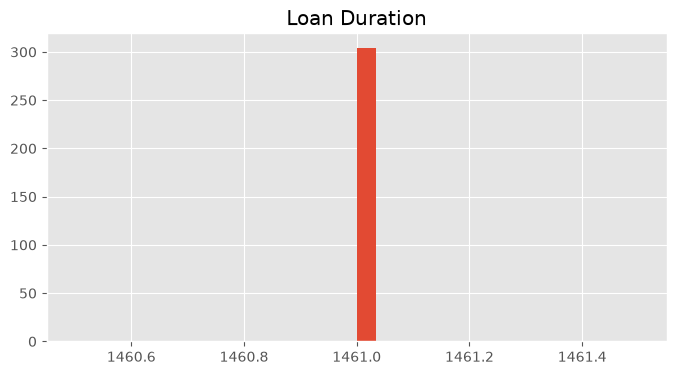

In [193]:
plt.figure(figsize=(8,4))

dettes["loan_duration_days"].hist(bins=30)

plt.title("Loan Duration")

plt.show()

Tous les credits ont une durée de 1461 jrs, donc ce feature n'a pas de valeur ajoutée et ne sera pas consideré 

Distribution des valeurs numeriques 

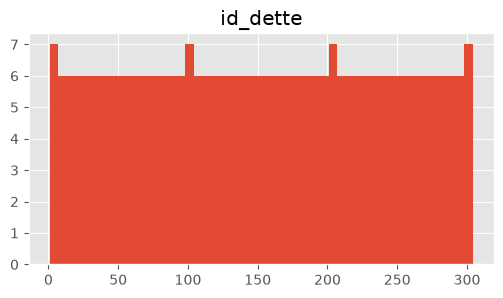

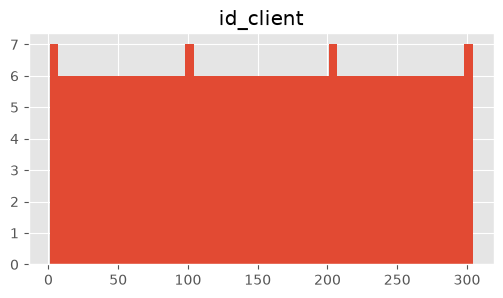

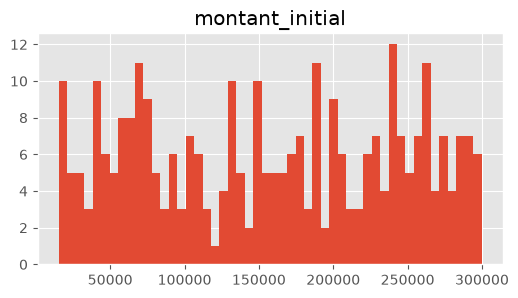

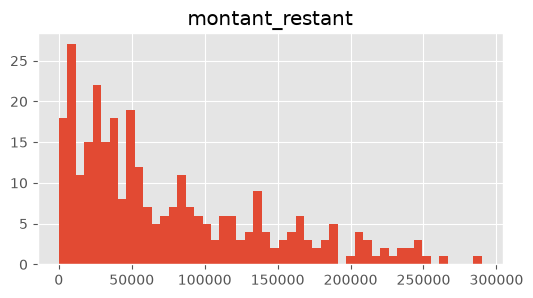

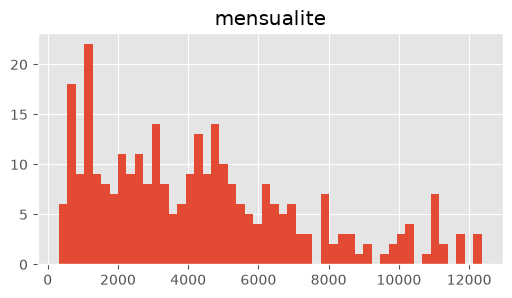

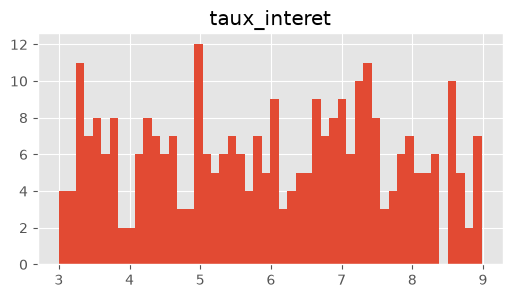

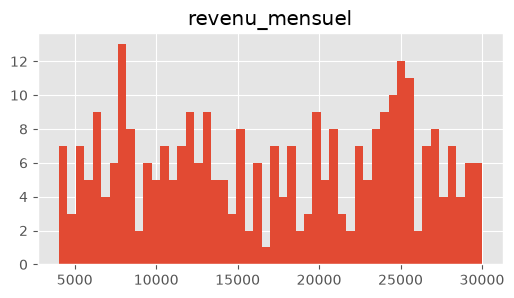

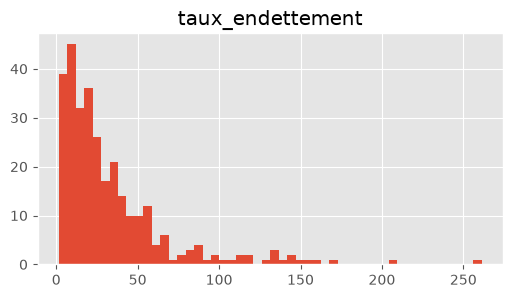

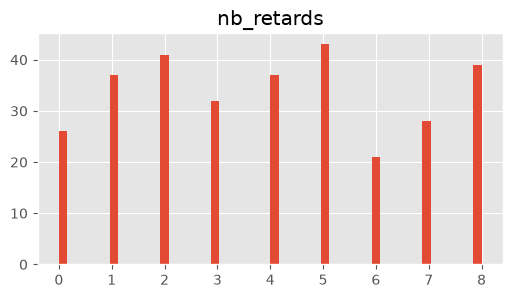

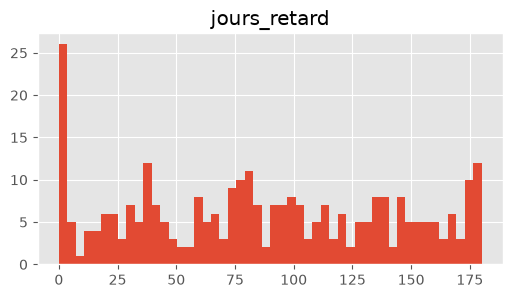

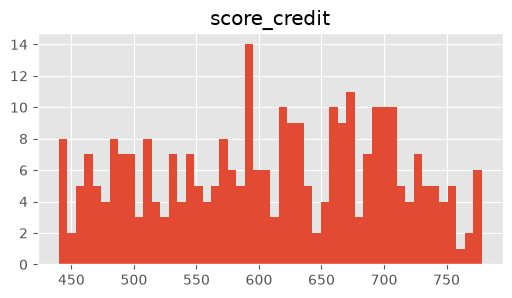

In [194]:
import matplotlib.pyplot as plt

for col in numerical:

    plt.figure(figsize=(6,3))

    dettes[col].hist(bins=50)

    plt.title(col)

    plt.show()

detection des outliers 

C:\Users\rayan\AppData\Local\Temp\ipykernel_24264\2159124732.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(dettes[col], vert=False)


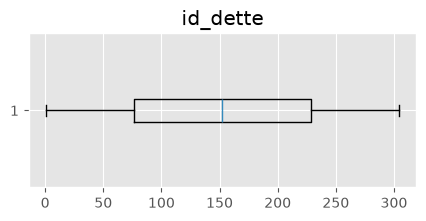

C:\Users\rayan\AppData\Local\Temp\ipykernel_24264\2159124732.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(dettes[col], vert=False)


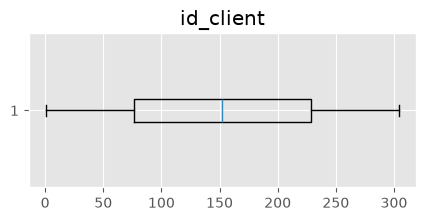

C:\Users\rayan\AppData\Local\Temp\ipykernel_24264\2159124732.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(dettes[col], vert=False)


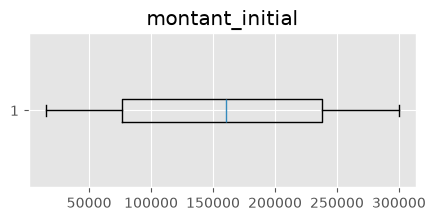

C:\Users\rayan\AppData\Local\Temp\ipykernel_24264\2159124732.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(dettes[col], vert=False)


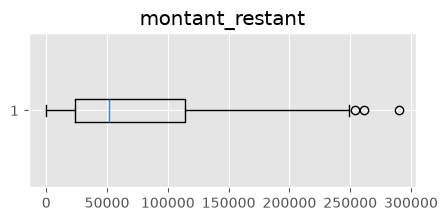

C:\Users\rayan\AppData\Local\Temp\ipykernel_24264\2159124732.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(dettes[col], vert=False)


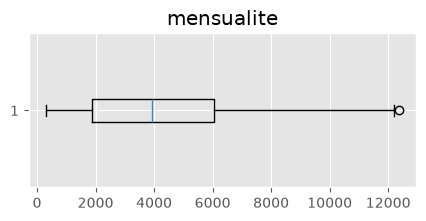

C:\Users\rayan\AppData\Local\Temp\ipykernel_24264\2159124732.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(dettes[col], vert=False)


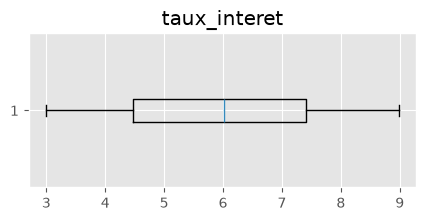

C:\Users\rayan\AppData\Local\Temp\ipykernel_24264\2159124732.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(dettes[col], vert=False)


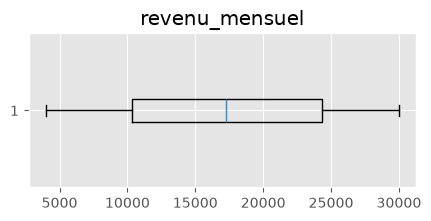

C:\Users\rayan\AppData\Local\Temp\ipykernel_24264\2159124732.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(dettes[col], vert=False)


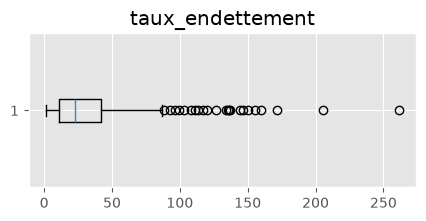

C:\Users\rayan\AppData\Local\Temp\ipykernel_24264\2159124732.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(dettes[col], vert=False)


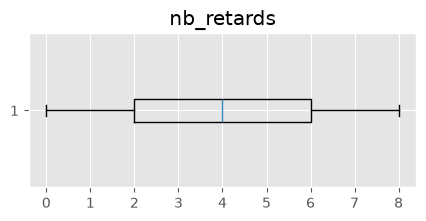

C:\Users\rayan\AppData\Local\Temp\ipykernel_24264\2159124732.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(dettes[col], vert=False)


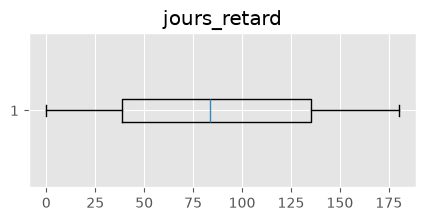

C:\Users\rayan\AppData\Local\Temp\ipykernel_24264\2159124732.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(dettes[col], vert=False)


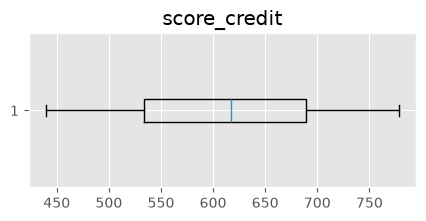

In [195]:
for col in numerical:

    plt.figure(figsize=(5,2))

    plt.boxplot(dettes[col], vert=False)

    plt.title(col)

    plt.show()

In [196]:
categorical = dettes.select_dtypes(include=["object","string"]).columns

for col in categorical:

    print("="*50)

    print(col)

    display(dettes[col].value_counts())

    print()

nom


nom
Wilson       13
David        13
Fournier     12
Lefevre      11
Garnier      11
Thomas       10
Faure        10
Rodriguez     9
Jackson       9
Blanc         9
Anderson      9
Simon         9
Girard        9
Moulin        9
Hernandez     8
Vincent       8
Richard       8
Taylor        8
Renaud        8
Moreau        8
Leroy         7
Mercier       7
Martinez      7
Gonzalez      7
Laurent       7
Durand        7
Moore         7
Lacroix       7
Garcia        7
Bonnin        6
Michel        6
Roux          6
Rousseau      6
Lopez         5
Dubois        4
Berger        4
Lambert       4
Petit         4
Dupont        3
Robert        2
Name: count, dtype: int64


prenom


prenom
Suzanne        18
Nathalie       17
Bernard        17
Marguerite     16
André          15
Paul           15
Françoise      14
Jacques        14
Jean-Pierre    12
Marie          12
Michel         10
Nicole         10
Catherine      10
Madeleine      10
Monique         9
Pierre          9
Jeanne          9
François        9
Louis           8
Martine         8
Daniel          8
Sophie          7
Véronique       7
Christine       7
Jean            7
Henri           6
Philippe        6
Denis           5
Alain           5
Isabelle        4
Name: count, dtype: int64


specialite


specialite
Agriculteur            20
Peintre en bâtiment    19
Artisan                18
Avocat                 17
Commerçant             15
Analyste financier     15
Mécanicien             15
Chauffeur              15
Médecin                15
Développeur            15
Ingénieur              13
Fermier                12
Coiffeur               12
Vendeur                12
Ouvrier BTP            12
Jardinier              11
Architecte             11
Enseignant             11
Consultant             10
Comptable               9
Banquier                8
Plombier                7
Infirmier               6
Électricien             6
Name: count, dtype: int64

... (8 outputs left out)


statut_dette


statut_dette
En retard    278
En cours      26
Name: count, dtype: int64


statut_paiement


statut_paiement
Non payé    223
Payé         81
Name: count, dtype: int64

In [197]:
dettes["taux_endettement"].describe()

count    304.000000
mean      34.061842
std       36.073560
min        1.600000
25%       10.800000
50%       22.450000
75%       41.675000
max      261.200000
Name: taux_endettement, dtype: float64

La matrice de correlation 

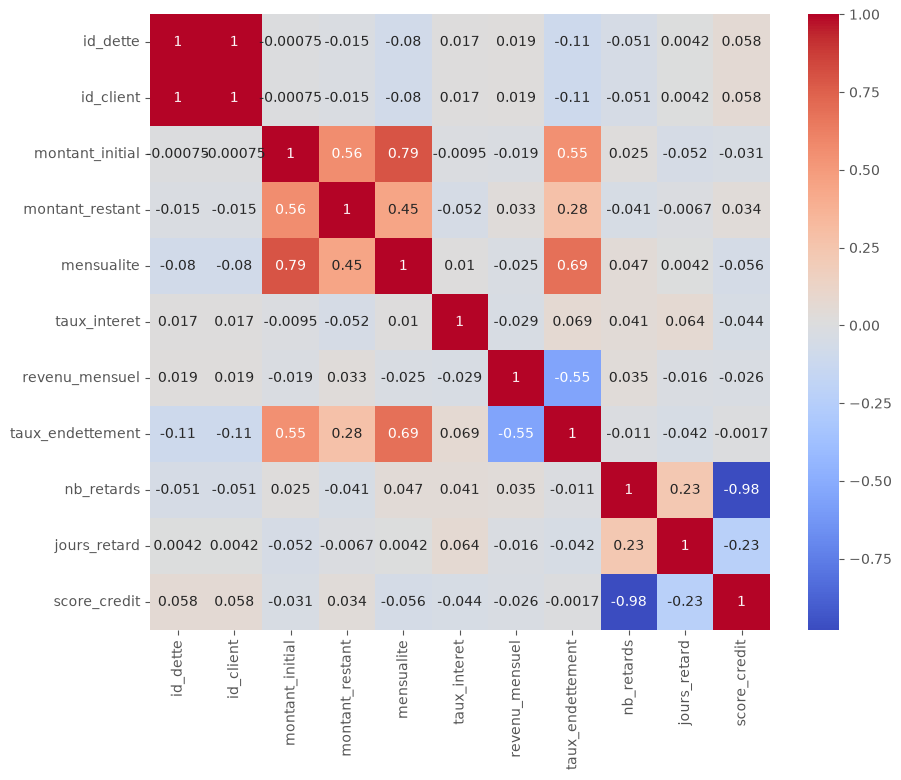

In [198]:
plt.figure(figsize=(10,8))

sns.heatmap(
    dettes[numerical].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.show()

est ce que chaque client a des promesses ?

In [203]:
# Qualification + Promise

eda = qualifications.copy()

eda = eda.merge(
    promesses[["id_qualification"]],
    on="id_qualification",
    how="left",
    indicator=True
)

eda["promise"] = (eda["_merge"] == "both").astype(int)

eda.drop(columns="_merge", inplace=True)

print(eda["promise"].value_counts())

display(eda.head())

promise
0    12443
1      672
Name: count, dtype: int64


,id_qualification,id_client,date_qualification,type,statut,promise
0,3273,94,2025-09-12,SMS,Joignable,0
1,12310,294,2024-06-21,Deplacement,Joignable,0
2,878,28,2024-07-24,Deplacement,Joignable,0
3,1490,29,2024-03-24,Deplacement,Joignable,0
4,2861,62,2025-12-18,Email,En cours,0


In [204]:
eda = (
    eda

    .merge(
        clients,
        on="id_client",
        how="left"
    )

    .merge(
        dettes,
        on="id_client",
        how="left",
        suffixes=("","_dette")
    )

    .merge(
        gestionnaires[
            ["id_gestionnaire","specialisation"]
        ],
        on="id_gestionnaire",
        how="left"
    )
)

print(eda.shape)

display(eda.head())

(13115, 38)


,id_qualification,id_client,date_qualification,type,statut,promise,nom,prenom,specialite,adresse,ville,region,id_gestionnaire,id_dette,nom_dette,prenom_dette,specialite_dette,adresse_dette,ville_dette,region_dette,montant_initial,montant_restant,mensualite,date_debut,date_echeance,taux_interet,type_credit,revenu_mensuel,taux_endettement,nb_retards,jours_retard,score_credit,statut_dette,statut_paiement,loan_duration_days,loan_start_year,loan_start_month,specialisation
0,3273,94,2025-09-12,SMS,Joignable,0,Rousseau,Madeleine,Chauffeur,"85 Boulevard Abdelmoumen, Oujda",Oujda,L'Oriental,25,94,Rousseau,Madeleine,Chauffeur,"85 Boulevard Abdelmoumen, Oujda",Oujda,L'Oriental,189327,110778,3944.31,2024-01-01,2028-01-01,3.28,Personnel,8427,46.8,2,176,684,En retard,Non payé,1461,2024,1,Telephonique
1,12310,294,2024-06-21,Deplacement,Joignable,0,Anderson,Monique,Fermier,"39 Boulevard Zerktouni, Tanger",Tanger,Tanger-Tétouan-Al Hoceïma,73,294,Anderson,Monique,Fermier,"39 Boulevard Zerktouni, Tanger",Tanger,Tanger-Tétouan-Al Hoceïma,240461,157778,6679.47,2024-01-01,2028-01-01,8.25,Auto,29977,22.3,8,130,444,En retard,Non payé,1461,2024,1,Terrain
2,878,28,2024-07-24,Deplacement,Joignable,0,Michel,Nicole,Consultant,"8 Rue Allal Ben Abdellah, Safi",Safi,Marrakech-Safi,7,28,Michel,Nicole,Consultant,"8 Rue Allal Ben Abdellah, Safi",Safi,Marrakech-Safi,179365,11916,4982.36,2024-01-01,2028-01-01,3.91,Personnel,25002,19.9,8,168,462,En retard,Non payé,1461,2024,1,Terrain
3,1490,29,2024-03-24,Deplacement,Joignable,0,Roux,Daniel,Comptable,"120 Boulevard Zerktouni, Safi",Safi,Marrakech-Safi,7,29,Roux,Daniel,Comptable,"120 Boulevard Zerktouni, Safi",Safi,Marrakech-Safi,259212,48724,4320.20,2024-01-01,2028-01-01,5.03,Professionnel,9810,44.0,3,151,617,En retard,Non payé,1461,2024,1,Terrain
4,2861,62,2025-12-18,Email,En cours,0,Garcia,Nathalie,Banquier,"110 Avenue des FAR, Meknès",Meknès,Fès-Meknès,16,62,Garcia,Nathalie,Banquier,"110 Avenue des FAR, Meknès",Meknès,Fès-Meknès,256754,130724,4279.23,2024-01-01,2028-01-01,4.51,Personnel,27142,15.8,3,90,659,En retard,Non payé,1461,2024,1,Telephonique


relation des variables avec Promesse:

In [205]:
numeric = eda.select_dtypes(include="number").columns

eda.groupby("promise")[numeric].mean().T

promise,0,1
id_qualification,6563.493932,6456.272321
id_client,149.951941,147.714286
promise,0.000000,1.000000
id_gestionnaire,37.810978,37.238095
id_dette,149.951941,147.714286
montant_initial,159027.814514,163682.369048
montant_restant,78501.088323,77500.156250
mensualite,4358.950588,4521.525268
taux_interet,5.905503,6.002187
revenu_mensuel,16503.444427,16200.169643


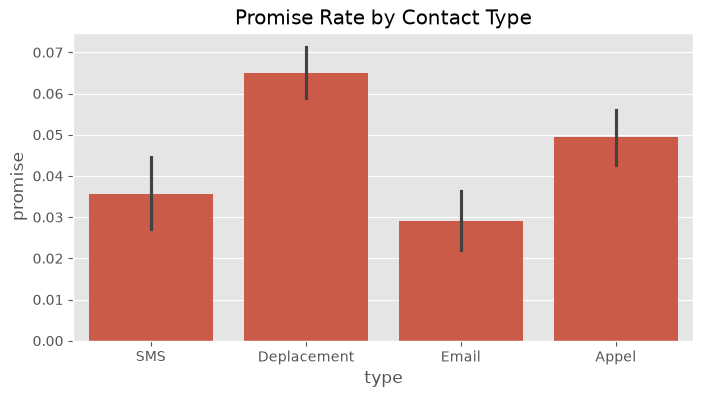

In [206]:
plt.figure(figsize=(8,4))

sns.barplot(
    data=eda,
    x="type",
    y="promise"
)

plt.title("Promise Rate by Contact Type")

plt.show()

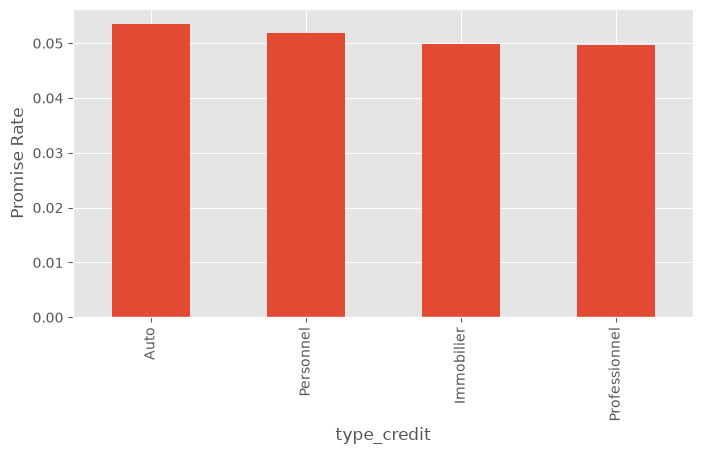

In [207]:
rates = (
    eda.groupby("type_credit")["promise"]
    .mean()
    .sort_values(ascending=False)
)

rates.plot.bar(figsize=(8,4))

plt.ylabel("Promise Rate")

plt.show()

Correlation avec la variable cible

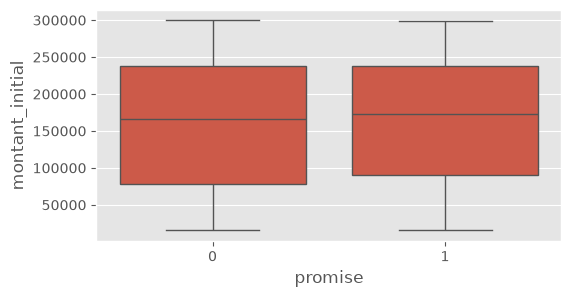

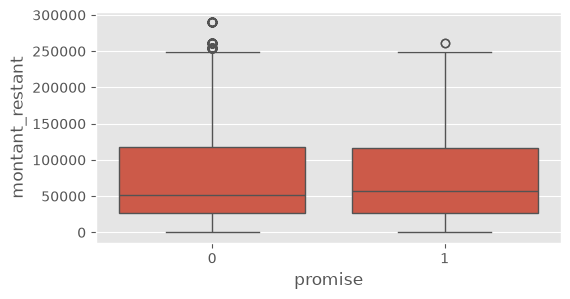

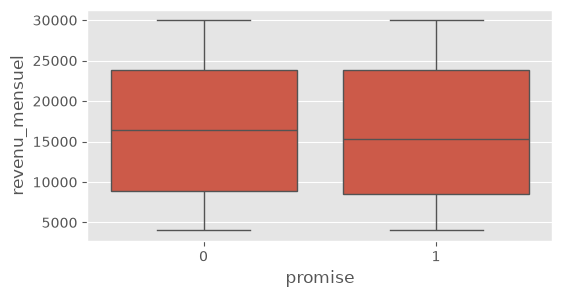

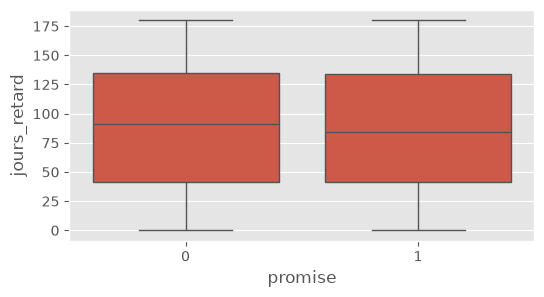

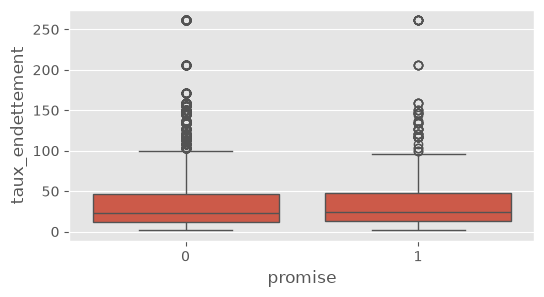

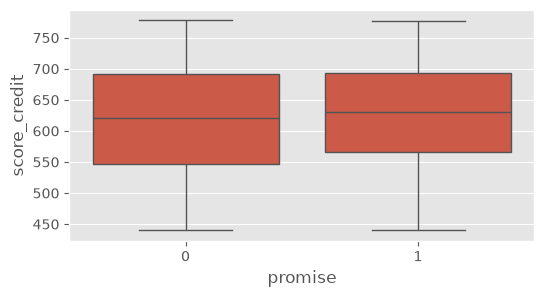

In [208]:
important = [
    "montant_initial",
    "montant_restant",
    "revenu_mensuel",
    "jours_retard",
    "taux_endettement",
    "score_credit"
]

for col in important:

    plt.figure(figsize=(6,3))

    sns.boxplot(
        data=eda,
        x="promise",
        y=col
    )

    plt.show()